# Can Probability Predict a Flood?
### Mumbai (Santacruz) extreme rainfall: a full statistical workflow

Probability and Statistics lab project · Vani Singh, Linga Chaitra

**Question.** On 26 July 2005, Santacruz recorded 944 mm of rain in 24 hours. Was that a freak event, or a measurable risk the city could have planned for?

**Workflow.** Each stage maps to one theme in the project brief:

| Stage | Brief theme | Tools |
|---|---|---|
| 1. Clean the gauge record | Descriptive statistics | completeness rule, documented corrections |
| 2. Describe the data | Descriptive statistics and visualisation | mean, median, mode, variance, skewness, histogram, box plot |
| 3. Fit distributions | Random variables and distributions | Normal, Gamma, Gumbel, GEV, Binomial, Poisson, chi-square goodness of fit |
| 4. Test claims | Hypothesis testing | z, t, F, chi-square, ANOVA |
| 5. Model trends | Regression | simple and multiple linear regression |
| 6. Validate | Data analysis and validation | train/test split, predicted vs observed |

**Data.** NOAA GHCN-Daily, station IN012070800 (Bombay/Santacruz), daily precipitation in mm, Oct 1949 to Aug 2025.

In [1]:
from pathlib import Path
import json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy import stats as st
import statsmodels.api as sm
import statsmodels.formula.api as smf
from statsmodels.stats.multicomp import pairwise_tukeyhsd
from statsmodels.stats.stattools import durbin_watson
from statsmodels.stats.outliers_influence import variance_inflation_factor

ROOT = Path.cwd().parent if Path.cwd().name == "analysis" else Path.cwd()
RAW = ROOT / "data" / "raw" / "santacruz_ghcn_daily.csv"
PROC = ROOT / "data" / "processed"
FIG = ROOT / "analysis" / "figures"
WEB = ROOT / "docs" / "data"
for p in (PROC, FIG, WEB):
    p.mkdir(parents=True, exist_ok=True)

ALPHA = 0.05
MONSOON = [6, 7, 8, 9]
COVERAGE_MIN = 104
VERY_HEAVY = 115.6
EXTREME = 204.5
IMD_2005 = 944.0
RNG = np.random.default_rng(2005)

plt.rcParams.update({"figure.dpi": 110, "savefig.dpi": 160, "axes.spines.top": False, "axes.spines.right": False,
                     "axes.grid": True, "grid.alpha": 0.25, "font.size": 10})
BLUE, ORANGE, GREY = "#1f6f9f", "#c8641e", "#8a949c"
pd.set_option("display.precision", 3)

## 1 · Data cleaning

Raw gauge records are messy. We check for duplicates, negative values and gaps, then apply three documented rules.

1. **Season completeness.** Mumbai's annual maximum falls in the June to September monsoon in almost every year. A year is kept only if at least **104 of 122 monsoon days (85%)** were recorded. A year with many missing monsoon days could have missed its biggest storm.
2. **The 2005 correction.** GHCN stores 461 mm on 26 July 2005 and **0.0 mm on 27 July**. IMD's official Santacruz total for the storm is **944 mm** in 24 hours. GHCN dates each value by the end of its 24-hour window (8:30 am to 8:30 am IST). We checked this convention on 30 Aug 2017: GHCN has 331.0 mm, and IMD reported 331.4 mm for 8:30 am 29 Aug to 8:30 am 30 Aug. So the storm belongs on 27 July, and GHCN's 0.0 there is a recording failure. We set 27 July 2005 to 944 mm and mark 26 July as missing.
3. **No other edits.** Values after 1973 are often rounded to whole millimetres. That is a precision change, not an error, so we keep them.

In [2]:
raw = pd.read_csv(RAW, parse_dates=["DATE"])
print("rows:", len(raw), "| span:", raw.DATE.min().date(), "to", raw.DATE.max().date())
print("duplicate dates:", raw.duplicated("DATE").sum(), "| negative values:", (raw.rain_mm < 0).sum(), "| missing values:", raw.rain_mm.isna().sum())
full_days = pd.date_range(raw.DATE.min(), raw.DATE.max())
print("calendar days absent from the record:", len(full_days) - len(raw))
raw.loc[raw.DATE.between("2005-07-25", "2005-07-28"), ["DATE", "rain_mm"]]

rows: 19808 | span: 1949-10-01 to 2025-08-24
duplicate dates: 0 | negative values: 0 | missing values: 0
calendar days absent from the record: 7914


,DATE,rain_mm
17291,2005-07-25,4.1
17292,2005-07-26,461.0
17293,2005-07-27,0.0
17294,2005-07-28,19.1


In [3]:
daily = raw.copy()
daily.loc[daily.DATE == "2005-07-26", "rain_mm"] = np.nan
daily.loc[daily.DATE == "2005-07-27", "rain_mm"] = IMD_2005
daily = daily.dropna(subset=["rain_mm"])
daily["year"] = daily.DATE.dt.year
daily["month"] = daily.DATE.dt.month

season = daily[daily.month.isin(MONSOON)]
coverage = season.groupby("year").rain_mm.count().reindex(range(1950, 2026), fill_value=0)
valid_years = coverage[coverage >= COVERAGE_MIN].index
dropped = coverage[coverage < COVERAGE_MIN]
print(f"years kept: {len(valid_years)} of {len(coverage)} ({valid_years.min()} to {valid_years.max()})")
print("years dropped (monsoon days recorded):", dict(dropped))

years kept: 63 of 76 (1950 to 2024)
years dropped (monsoon days recorded): {1971: np.int64(0), 1972: np.int64(0), 1973: np.int64(100), 1975: np.int64(0), 1976: np.int64(2), 1977: np.int64(91), 1983: np.int64(103), 2000: np.int64(88), 2009: np.int64(97), 2014: np.int64(102), 2015: np.int64(99), 2022: np.int64(97), 2025: np.int64(84)}


In [4]:
kept = daily[daily.year.isin(valid_years)]
idx = kept.groupby("year").rain_mm.idxmax()
annual = kept.loc[idx, ["year", "DATE", "rain_mm"]].rename(columns={"DATE": "max_date", "rain_mm": "max_mm"}).set_index("year")

js = season[season.year.isin(valid_years)].groupby("year").agg(
    days=("rain_mm", "count"),
    total_mm=("rain_mm", "sum"),
    wet_days=("rain_mm", lambda x: int((x >= 2.5).sum())),
    very_heavy_days=("rain_mm", lambda x: int((x >= VERY_HEAVY).sum())),
    extreme_days=("rain_mm", lambda x: int((x >= EXTREME).sum())),
)
js["total_adj_mm"] = js.total_mm / js.days * 122
annual = annual.join(js)
annual["period"] = np.where(annual.index <= 1987, "1950-1987", "1988-2024")
annual.to_csv(PROC / "annual_series.csv")
print(f"cleaned series: {len(annual)} years")
annual.head()

cleaned series: 63 years


,max_date,max_mm,days,total_mm,wet_days,very_heavy_days,extreme_days,total_adj_mm,period
year,,,,,,,,,
1950,1950-07-08,154.9,122,1797.0,63,3,0,1797.0,1950-1987
1951,1951-07-25,129.5,118,1616.6,59,1,0,1671.4,1950-1987
1952,1952-07-17,308.6,122,2338.4,63,8,4,2338.4,1950-1987
1953,1953-07-28,310.6,122,2589.5,72,4,2,2589.5,1950-1987
1954,1954-08-07,256.0,122,3444.6,83,6,2,3444.6,1950-1987


Monsoon totals use **coverage-adjusted** values: the mean daily rain on recorded days × 122. This stops a season with a few missing days from looking drier than it was. Counts of heavy days use only recorded days, so they are a slight undercount in years with gaps.

The heavy-day thresholds are IMD's categories: **very heavy rain ≥ 115.6 mm/day**, **extremely heavy rain ≥ 204.5 mm/day**.

## 2 · Descriptive statistics and visualisation

In [5]:
def describe(x):
    x = np.asarray(x, float)
    q1, q3 = np.percentile(x, [25, 75])
    counts, edges = np.histogram(x, bins=np.arange(0, x.max() + 50, 50))
    m = counts.argmax()
    return pd.Series({
        "n": len(x), "mean": x.mean(), "median": np.median(x),
        "mode (50 mm class)": f"{edges[m]:.0f}-{edges[m + 1]:.0f}",
        "variance": x.var(ddof=1), "std dev": x.std(ddof=1), "CV": x.std(ddof=1) / x.mean(),
        "min": x.min(), "Q1": q1, "Q3": q3, "max": x.max(), "IQR": q3 - q1,
        "skewness": st.skew(x, bias=False), "excess kurtosis": st.kurtosis(x, bias=False),
    })

desc = pd.DataFrame({
    "Annual max, all years": describe(annual.max_mm),
    "Annual max, without 2005": describe(annual.max_mm.drop(2005)),
    "Monsoon total (adj.)": describe(annual.total_adj_mm),
})
desc

,"Annual max, all years","Annual max, without 2005",Monsoon total (adj.)
n,63,62,63
mean,224.675,213.073,2367.964
median,193.0,192.8,2309.2
mode (50 mm class),150-200,150-200,2550-2600
variance,13954.077,5563.575,415555.148
std dev,118.127,74.589,644.636
CV,0.526,0.35,0.272
min,121.2,121.2,1208.33
Q1,157.9,157.85,1937.717
Q3,254.5,250.05,2592.12


In [6]:
x = annual.max_mm
q1, q3 = np.percentile(x, [25, 75])
fence = q3 + 1.5 * (q3 - q1)
outliers = annual.loc[x > fence, ["max_date", "max_mm"]]
print(f"upper box-plot fence: {fence:.1f} mm")
outliers

upper box-plot fence: 399.4 mm


,max_date,max_mm
year,,
2005,2005-07-27,944.0


In [7]:
vh_mode = annual.very_heavy_days.mode().tolist()
print("very-heavy days per monsoon: mean", round(annual.very_heavy_days.mean(), 2),
      "| median", annual.very_heavy_days.median(), "| mode", vh_mode,
      "| variance", round(annual.very_heavy_days.var(ddof=1), 2))

very-heavy days per monsoon: mean 3.62 | median 3.0 | mode [3] | variance 4.56


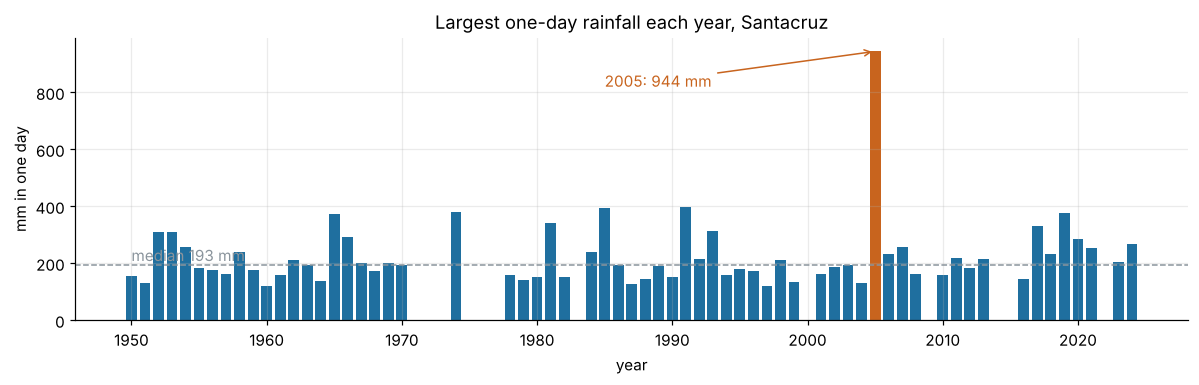

In [8]:
fig, ax = plt.subplots(figsize=(11, 3.6))
colors = [ORANGE if y == 2005 else BLUE for y in annual.index]
ax.bar(annual.index, annual.max_mm, color=colors, width=0.8)
ax.axhline(annual.max_mm.median(), color=GREY, ls="--", lw=1)
ax.text(annual.index.min(), annual.max_mm.median() + 15, f"median {annual.max_mm.median():.0f} mm", color=GREY)
ax.annotate("2005: 944 mm", (2005, 944), xytext=(1985, 820), arrowprops=dict(arrowstyle="->", color=ORANGE), color=ORANGE)
ax.set(title="Largest one-day rainfall each year, Santacruz", ylabel="mm in one day", xlabel="year")
fig.tight_layout(); fig.savefig(FIG / "01_annual_maxima.png"); plt.show()

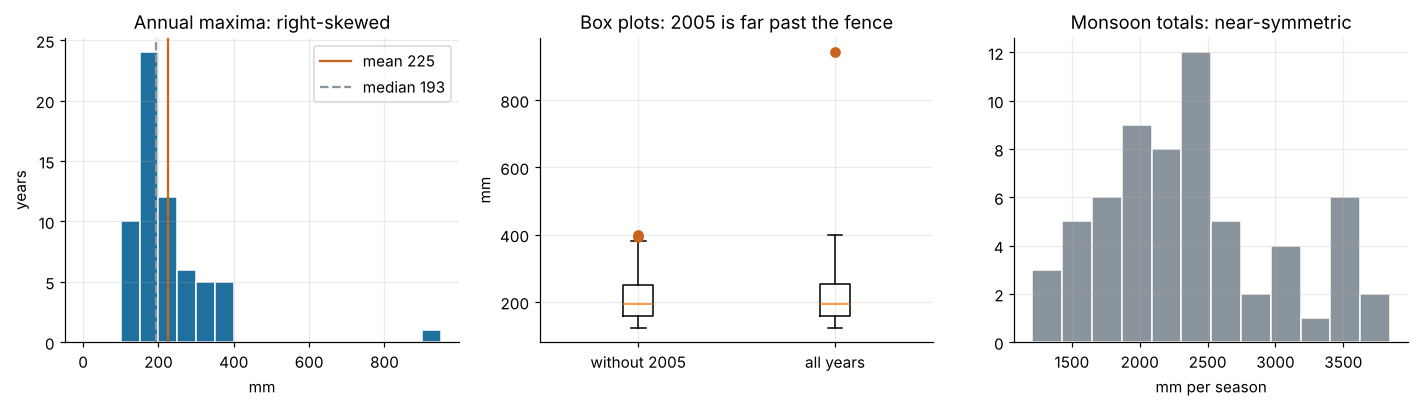

In [9]:
fig, axes = plt.subplots(1, 3, figsize=(13, 3.8))
axes[0].hist(annual.max_mm, bins=np.arange(0, 1000, 50), color=BLUE, edgecolor="white")
axes[0].axvline(annual.max_mm.mean(), color=ORANGE, lw=1.5, label=f"mean {annual.max_mm.mean():.0f}")
axes[0].axvline(annual.max_mm.median(), color=GREY, lw=1.5, ls="--", label=f"median {annual.max_mm.median():.0f}")
axes[0].legend(); axes[0].set(title="Annual maxima: right-skewed", xlabel="mm", ylabel="years")
axes[1].boxplot([annual.max_mm.drop(2005), annual.max_mm], tick_labels=["without 2005", "all years"],
                flierprops=dict(markerfacecolor=ORANGE, markeredgecolor=ORANGE))
axes[1].set(title="Box plots: 2005 is far past the fence", ylabel="mm")
axes[2].hist(annual.total_adj_mm, bins=12, color=GREY, edgecolor="white")
axes[2].set(title="Monsoon totals: near-symmetric", xlabel="mm per season")
fig.tight_layout(); fig.savefig(FIG / "02_histograms_boxplots.png"); plt.show()

**Reading the shapes.** For annual maxima the mean is above the median and the skewness is strongly positive, so the distribution has a long right tail. Even without 2005 the skew stays clearly positive. Monsoon totals are close to symmetric. That difference drives the next section: totals behave like a Normal variable, but extremes do not.

## 3 · Random variables and probability distributions

**3a. Which model fits the annual maximum?** We fit four candidates by maximum likelihood:

- **Normal**: the brief's default.
- **Gamma**: the model used in the presentation.
- **Gumbel**: the classic extreme-value model, with a light tail.
- **GEV (Generalised Extreme Value)**: the distribution extreme-value theory predicts for block maxima such as annual maxima. Its shape parameter ξ decides how heavy the tail is.

To test the claim fairly, we first fit **only 1950–2004**, the data available before the flood, and ask what each model would have said about 944 mm.

Goodness of fit uses a **chi-square test with equal-probability bins** (expected count ≥ 5 per bin, df = bins − 1 − fitted parameters). The **Kolmogorov–Smirnov** test and **AIC** serve as cross-checks.

In [10]:
PARAMS = {"Normal": 2, "Gamma": 2, "Gumbel": 2, "GEV": 3}

def fit_all(x):
    a, _, s = st.gamma.fit(x, floc=0)
    c, l, sc = st.genextreme.fit(x)
    return {"Normal": st.norm(*st.norm.fit(x)), "Gamma": st.gamma(a, 0, s),
            "Gumbel": st.gumbel_r(*st.gumbel_r.fit(x)), "GEV": st.genextreme(c, l, sc)}

def chi_square_gof(x, dist, k_params, bins):
    edges = dist.ppf(np.linspace(0, 1, bins + 1))
    obs = np.histogram(x, edges)[0]
    exp = len(x) / bins
    chi = ((obs - exp) ** 2 / exp).sum()
    df = bins - 1 - k_params
    return chi, df, st.chi2.ppf(1 - ALPHA, df), st.chi2.sf(chi, df)

def fit_table(x, bins):
    rows = []
    for name, dist in fit_all(x).items():
        k = PARAMS[name]
        chi, df, crit, p = chi_square_gof(x, dist, k, bins)
        rows.append({"model": name, "chi2": chi, "df": df, "critical": crit, "p_chi2": p,
                     "p_KS": st.kstest(x, dist.cdf).pvalue, "AIC": 2 * k - 2 * dist.logpdf(x).sum(),
                     "verdict": "fits" if p > ALPHA else "rejected",
                     "2-yr": dist.isf(1 / 2), "10-yr": dist.isf(1 / 10), "50-yr": dist.isf(1 / 50), "100-yr": dist.isf(1 / 100),
                     "return period of 944 mm (yr)": 1 / dist.sf(IMD_2005)})
    return pd.DataFrame(rows).set_index("model")

pre = annual.loc[:2004, "max_mm"].values
fits_pre = fit_all(pre)
table_pre = fit_table(pre, bins=6)
print(f"fitted on 1950-2004, n = {len(pre)} years, 6 equal-probability bins")
table_pre

fitted on 1950-2004, n = 47 years, 6 equal-probability bins


,chi2,df,critical,p_chi2,p_KS,AIC,verdict,2-yr,10-yr,50-yr,100-yr,return period of 944 mm (yr)
model,,,,,,,,,,,,
Normal,15.426,3,7.815,0.001,0.032,544.748,rejected,206.189,303.877,362.738,383.517,5.415e+21
Gamma,7.766,3,7.815,0.051,0.146,532.842,fits,198.357,299.238,373.573,402.364,1.686e+09
Gumbel,4.447,3,7.815,0.217,0.495,527.560,fits,191.926,286.908,370.178,405.382,4.338e+06
GEV,0.872,2,5.991,0.647,0.946,522.774,fits,180.890,307.066,514.674,646.841,3.076e+02


In [11]:
gev_pre = fits_pre["GEV"]
c, loc, scale = gev_pre.args
print(f"GEV (1950-2004): location {loc:.1f} mm, scale {scale:.1f} mm, shape xi = {-c:.3f}  (xi > 0 means a heavy, unbounded tail)")

GEV (1950-2004): location 164.8 mm, scale 41.1 mm, shape xi = 0.359  (xi > 0 means a heavy, unbounded tail)


**Uncertainty of the tail.** A 47-year record says little about events rarer than about 1 in 50 years, so the 100-year level and the 944 mm return period need intervals. We use a **non-parametric bootstrap**: resample the 47 years with replacement 1,000 times, refit the GEV each time, and read off the 2.5th and 97.5th percentiles. Each refit starts from the original estimates, so the optimiser does not wander into degenerate solutions.

In [12]:
def bootstrap_gev(x, B=1000):
    c0, l0, s0 = st.genextreme.fit(x)
    out = []
    for _ in range(B):
        s = RNG.choice(x, size=len(x), replace=True)
        c, l, sc = st.genextreme.fit(s, c0, loc=l0, scale=s0)
        d = st.genextreme(c, l, sc)
        out.append((d.isf(1 / 100), 1 / max(d.sf(IMD_2005), 1e-300), -c))
    return pd.DataFrame(out, columns=["rl100", "T944", "xi"])

boot_pre = bootstrap_gev(pre)
ci = boot_pre.quantile([0.025, 0.5, 0.975])
ci_text = {
    "100-yr level (mm)": f"{gev_pre.isf(0.01):.0f}  [95% CI {ci.rl100.iloc[0]:.0f} to {ci.rl100.iloc[2]:.0f}]",
    "return period of 944 mm (yr)": f"{1 / gev_pre.sf(IMD_2005):.0f}  [95% CI {ci.T944.iloc[0]:.0f} to {ci.T944.iloc[2]:,.0f}]",
    "shape xi": f"{-gev_pre.args[0]:.2f}  [95% CI {ci.xi.iloc[0]:.2f} to {ci.xi.iloc[2]:.2f}]",
    "share of resamples with xi > 0": f"{(boot_pre.xi > 0).mean():.0%}",
}
pd.Series(ci_text, name="GEV fitted on 1950-2004")

100-yr level (mm)                   647  [95% CI 416 to 1217]
return period of 944 mm (yr)       308  [95% CI 65 to 12,299]
shape xi                          0.36  [95% CI 0.14 to 0.64]
share of resamples with xi > 0                           100%
Name: GEV fitted on 1950-2004, dtype: str

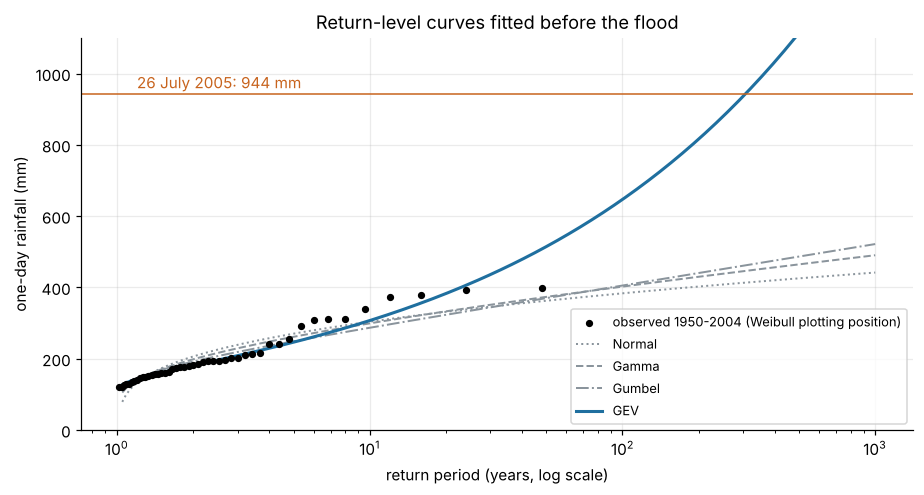

In [13]:
xs = np.sort(pre)
n = len(xs)
T_emp = (n + 1) / (n - np.arange(1, n + 1) + 1)
Ts = np.logspace(np.log10(1.05), np.log10(1000), 200)
fig, ax = plt.subplots(figsize=(8.5, 4.6))
ax.scatter(T_emp, xs, color="black", s=14, zorder=3, label="observed 1950-2004 (Weibull plotting position)")
for name, col, ls in [("Normal", GREY, ":"), ("Gamma", GREY, "--"), ("Gumbel", GREY, "-."), ("GEV", BLUE, "-")]:
    ax.plot(Ts, fits_pre[name].isf(1 / Ts), color=col, ls=ls, lw=2 if name == "GEV" else 1.3, label=name)
ax.axhline(IMD_2005, color=ORANGE, lw=1)
ax.text(1.2, IMD_2005 + 15, "26 July 2005: 944 mm", color=ORANGE)
ax.set_xscale("log"); ax.set(xlabel="return period (years, log scale)", ylabel="one-day rainfall (mm)",
                             title="Return-level curves fitted before the flood", ylim=(0, 1100))
ax.legend(loc="lower right", fontsize=8.5)
fig.tight_layout(); fig.savefig(FIG / "03_return_levels_pre2005.png"); plt.show()

**The full record (1950–2024, including 2005).** Refitting with every year shows how a single event moves the estimates. The deployed calculator uses this fit.

In [14]:
allx = annual.max_mm.values
fits_all = fit_all(allx)
table_all = fit_table(allx, bins=8)
print(f"fitted on all {len(allx)} years, 8 equal-probability bins")
table_all

fitted on all 63 years, 8 equal-probability bins


,chi2,df,critical,p_chi2,p_KS,AIC,verdict,2-yr,10-yr,50-yr,100-yr,return period of 944 mm (yr)
model,,,,,,,,,,,,
Normal,32.111,5,11.070,5.648e-06,0.020,783.020,rejected,224.675,374.855,465.345,497.290,2.398e+09
Gamma,13.571,5,11.070,1.857e-02,0.175,742.923,rejected,212.741,345.147,445.891,485.421,1.253e+06
Gumbel,10.524,5,11.070,6.168e-02,0.458,731.601,fits,206.269,320.443,420.540,462.856,2.790e+05
GEV,2.143,4,9.488,7.095e-01,0.992,717.489,fits,191.466,339.832,590.292,752.359,1.898e+02


In [15]:
boot_all = bootstrap_gev(allx)
gev_all = fits_all["GEV"]
ci_all = boot_all.quantile([0.025, 0.975])
rl_rows = []
for T in (2, 5, 10, 25, 50, 100, 200):
    rl_rows.append({"return period (yr)": T, "GEV level (mm)": gev_all.isf(1 / T),
                    "Gamma level (mm)": fits_all["Gamma"].isf(1 / T),
                    "annual exceedance probability": 1 / T})
rl_all = pd.DataFrame(rl_rows).set_index("return period (yr)")
print(f"GEV full record: xi = {-gev_all.args[0]:.2f}; 100-yr level {gev_all.isf(0.01):.0f} mm "
      f"[95% CI {ci_all.rl100.iloc[0]:.0f} to {ci_all.rl100.iloc[1]:.0f}]")
rl_all

GEV full record: xi = 0.37; 100-yr level 752 mm [95% CI 453 to 1312]


,GEV level (mm),Gamma level (mm),annual exceedance probability
return period (yr),,,
2,191.466,212.741,0.500
5,268.055,294.950,0.200
10,339.832,345.147,0.100
25,464.602,404.394,0.040
50,590.292,445.891,0.020
100,752.359,485.421,0.010
200,961.818,523.458,0.005


**3b. Binomial: what a "100-year" level means.** Treat each year as a Bernoulli trial with success probability p = 1/T, where success means the T-year level is exceeded. The number of exceedances in n years is then **Binomial(n, p)**:

- P(at least one in n years) = 1 − (1 − p)ⁿ
- E[X] = np
- SD = √(np(1 − p))

The waiting time to the first exceedance is **Geometric**, with mean T.

In [16]:
horizon = pd.DataFrame({f"T = {T} yr": [1 - (1 - 1 / T) ** n for n in (10, 30, 50, 100)] for T in (10, 50, 100, 300)},
                       index=pd.Index([10, 30, 50, 100], name="years (n)"))
horizon.style.format("{:.1%}")

,T = 10 yr,T = 50 yr,T = 100 yr,T = 300 yr
years (n),,,,
10,65.1%,18.3%,9.6%,3.3%
30,95.8%,45.5%,26.0%,9.5%
50,99.5%,63.6%,39.5%,15.4%
100,100.0%,86.7%,63.4%,28.4%


In [17]:
rows = []
for T in (2, 10, 50):
    level = fits_pre["GEV"].isf(1 / T)
    obs = int((pre > level).sum())
    p = 1 / T
    mean, sd = len(pre) * p, np.sqrt(len(pre) * p * (1 - p))
    rows.append({"level": f"{T}-yr ({level:.0f} mm)", "expected np": mean, "SD": sd, "observed": obs,
                 "z = (obs - np) / SD": (obs - mean) / sd,
                 "exact binomial p": st.binomtest(obs, len(pre), p).pvalue})
pd.DataFrame(rows).set_index("level")

,expected np,SD,observed,z = (obs - np) / SD,exact binomial p
level,,,,,
2-yr (181 mm),23.50,3.428,24,0.146,1.000
10-yr (307 mm),4.70,2.057,8,1.605,0.137
50-yr (515 mm),0.94,0.960,0,-0.979,1.000


In-sample, the GEV's predicted exceedance counts match the observed counts closely, as they should for a model fitted to the same data. The honest out-of-sample version of this check is in Section 6.

**3c. Poisson: counting very heavy rain days.** The number of very heavy days (≥ 115.6 mm) in a monsoon counts rare events over a fixed window. That makes **Poisson(λ)** the natural model, with λ estimated as the sample mean. We test the fit with a chi-square goodness-of-fit test and check the Poisson assumption that variance equals mean.

In [18]:
counts = annual.very_heavy_days.values
lam = counts.mean()
cats = [0, 1, 2, 3, 4, 5, 6]
pois_obs = np.array([(counts == k).sum() for k in cats[:-1]] + [(counts >= cats[-1]).sum()])
probs = np.array([st.poisson.pmf(k, lam) for k in cats[:-1]] + [st.poisson.sf(cats[-1] - 1, lam)])
exp = probs * len(counts)
merged_obs = np.array([pois_obs[:2].sum(), *pois_obs[2:]])
merged_exp = np.array([exp[:2].sum(), *exp[2:]])
chi = ((merged_obs - merged_exp) ** 2 / merged_exp).sum()
df = len(merged_obs) - 1 - 1
dispersion = counts.var(ddof=1) / lam
D = (len(counts) - 1) * dispersion
pois = pd.DataFrame({"observed years": pois_obs, "Poisson expected": exp}, index=["0", "1", "2", "3", "4", "5", "6+"])
print(f"lambda = {lam:.2f} very heavy days per monsoon | variance = {counts.var(ddof=1):.2f} | dispersion index = {dispersion:.2f}")
print(f"chi-square GOF (0 and 1 merged so every expected count >= 5): chi2 = {chi:.2f}, df = {df}, critical = {st.chi2.ppf(0.95, df):.2f}, p = {st.chi2.sf(chi, df):.3f}")
print(f"dispersion test: D = {D:.1f} on {len(counts) - 1} df, p = {st.chi2.sf(D, len(counts) - 1):.3f}")
pois

lambda = 3.62 very heavy days per monsoon | variance = 4.56 | dispersion index = 1.26
chi-square GOF (0 and 1 merged so every expected count >= 5): chi2 = 5.33, df = 4, critical = 9.49, p = 0.255
dispersion test: D = 78.2 on 62 df, p = 0.081


,observed years,Poisson expected
0,0,1.689
1,9,6.112
2,13,11.060
3,14,13.343
4,11,12.072
5,3,8.738
6+,13,9.986


In [19]:
lam_ex = annual.extreme_days.mean()
pred = pd.Series({
    "dispersion index, extremely heavy days": annual.extreme_days.var(ddof=1) / lam_ex,
    "P(no very heavy day in a monsoon)": st.poisson.pmf(0, lam),
    "P(5 or more very heavy days)": st.poisson.sf(4, lam),
    "P(at least one extremely heavy day >= 204.5 mm)": 1 - np.exp(-lam_ex),
    "observed share of monsoons with an extremely heavy day": (annual.extreme_days > 0).mean(),
})
pred = pd.Series({k: (f"{v:.2f}" if k.startswith("dispersion") else f"{v:.1%}") for k, v in pred.items()})
print(f"lambda (extremely heavy days) = {lam_ex:.2f} per monsoon")
pred

lambda (extremely heavy days) = 0.75 per monsoon


dispersion index, extremely heavy days                     1.56
P(no very heavy day in a monsoon)                          2.7%
P(5 or more very heavy days)                              29.7%
P(at least one extremely heavy day >= 204.5 mm)           52.6%
observed share of monsoons with an extremely heavy day    41.3%
dtype: str

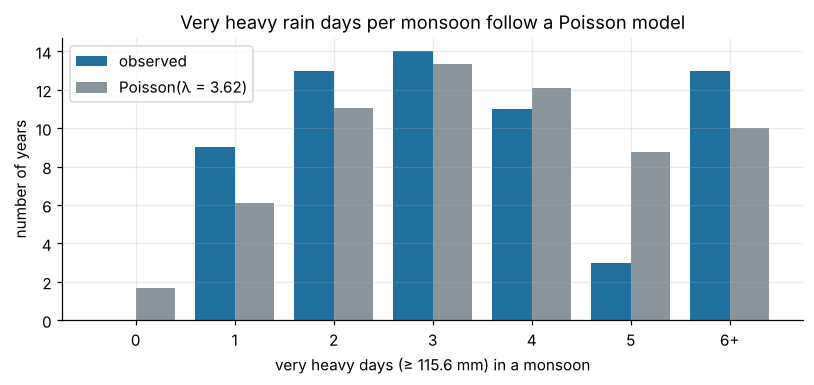

In [20]:
fig, ax = plt.subplots(figsize=(7.5, 3.6))
pos = np.arange(len(pois))
ax.bar(pos - 0.2, pois["observed years"], 0.4, color=BLUE, label="observed")
ax.bar(pos + 0.2, pois["Poisson expected"], 0.4, color=GREY, label=f"Poisson(λ = {lam:.2f})")
ax.set_xticks(pos, pois.index); ax.set(xlabel="very heavy days (≥ 115.6 mm) in a monsoon", ylabel="number of years",
                                       title="Very heavy rain days per monsoon follow a Poisson model")
ax.legend(); fig.tight_layout(); fig.savefig(FIG / "04_poisson_heavy_days.png"); plt.show()

**3d. Normal: where it does work.** A monsoon total is a sum of 122 daily amounts, so the Central Limit Theorem pushes it toward a Normal shape. We test this with Shapiro–Wilk on two versions:

- the raw totals;
- the totals after removing the long-term trend found in Section 5, i.e. the regression residuals.

A trend mixes a drier and a wetter era into one sample, and that alone can make a Normal variable look non-Normal.

In [21]:
tot = annual.total_adj_mm.values
mu, sd = tot.mean(), tot.std(ddof=1)
verdict = lambda p: "Normal rejected" if p < ALPHA else "Normal not rejected"
detr = sm.OLS(tot, sm.add_constant(annual.index.values.astype(float))).fit()
resid_sd = np.sqrt(detr.scale)
sw = st.shapiro(tot)
sw_res = st.shapiro(detr.resid)
sw_max = st.shapiro(annual.max_mm.values)
tcrit = st.t.ppf(0.975, len(tot) - 1)
half = tcrit * sd / np.sqrt(len(tot))
print(f"annual maxima:           W = {sw_max.statistic:.3f}, p = {sw_max.pvalue:.2g} -> {verdict(sw_max.pvalue)}")
print(f"monsoon totals (raw):    W = {sw.statistic:.3f}, p = {sw.pvalue:.3f} -> {verdict(sw.pvalue)}")
print(f"monsoon totals (detrended): W = {sw_res.statistic:.3f}, p = {sw_res.pvalue:.3f} -> {verdict(sw_res.pvalue)}")
print(f"mean monsoon total {mu:.0f} mm, 95% CI {mu - half:.0f} to {mu + half:.0f} mm (t = {tcrit:.3f}, df = {len(tot) - 1})")
for yr in (1960, 2024):
    m_y = detr.params[0] + detr.params[1] * yr
    print(f"P(total > 3000 mm) in a {yr} season under N({m_y:.0f}, {resid_sd:.0f}^2) = {st.norm.sf(3000, m_y, resid_sd):.1%}")
print(f"observed share of seasons above 3000 mm: 1950-1987 {(annual.loc[:1987].total_adj_mm > 3000).mean():.1%}, 1988-2024 {(annual.loc[1988:].total_adj_mm > 3000).mean():.1%}")

annual maxima:           W = 0.651, p = 5.8e-11 -> Normal rejected
monsoon totals (raw):    W = 0.957, p = 0.026 -> Normal rejected
monsoon totals (detrended): W = 0.984, p = 0.574 -> Normal not rejected
mean monsoon total 2368 mm, 95% CI 2206 to 2530 mm (t = 1.999, df = 62)
P(total > 3000 mm) in a 1960 season under N(2102, 609^2) = 7.0%
P(total > 3000 mm) in a 2024 season under N(2749, 609^2) = 34.0%
observed share of seasons above 3000 mm: 1950-1987 6.5%, 1988-2024 34.4%


## 4 · Hypothesis testing

Every test uses α = 0.05 and is two-sided unless stated otherwise.

**H1. Has the typical annual maximum changed?** We compare 1950–1987 with 1988–2024.

- H₀: μ₁ = μ₂
- H₁: μ₁ ≠ μ₂

The **F-test** checks whether the two variances are equal, which decides between the pooled and Welch t-test. **Mann–Whitney U** is a cross-check that does not assume normality.

In [22]:
early = annual.loc[annual.period == "1950-1987", "max_mm"]
late = annual.loc[annual.period == "1988-2024", "max_mm"]
F = late.var(ddof=1) / early.var(ddof=1)
dfn, dfd = len(late) - 1, len(early) - 1
pF = 2 * min(st.f.sf(F, dfn, dfd), st.f.cdf(F, dfn, dfd))
w = st.ttest_ind(early, late, equal_var=False)
mw = st.mannwhitneyu(early, late)
w2 = st.ttest_ind(early, late.drop(2005), equal_var=False)
print(f"means: {early.mean():.1f} mm (n={len(early)}) vs {late.mean():.1f} mm (n={len(late)})")
print(f"F-test: F = {F:.2f} on ({dfn}, {dfd}) df, two-sided critical {st.f.ppf(0.975, dfn, dfd):.2f}, p = {pF:.4f} -> " + ("variances differ, so use Welch" if pF < ALPHA else "equal variances not rejected"))
F2 = late.drop(2005).var(ddof=1) / early.var(ddof=1)
print(f"F-test without 2005: F = {F2:.2f}, p = {2 * min(st.f.sf(F2, dfn - 1, dfd), st.f.cdf(F2, dfn - 1, dfd)):.3f}")
print(f"Welch t = {w.statistic:.2f}, df = {w.df:.1f}, p = {w.pvalue:.3f}")
print(f"Welch without 2005: t = {w2.statistic:.2f}, p = {w2.pvalue:.3f} | Mann-Whitney U p = {mw.pvalue:.3f}")

means: 213.9 mm (n=31) vs 235.1 mm (n=32)
F-test: F = 3.39 on (31, 30) df, two-sided critical 2.07, p = 0.0012 -> variances differ, so use Welch
F-test without 2005: F = 0.78, p = 0.501
Welch t = -0.72, df = 48.1, p = 0.478
Welch without 2005: t = 0.09, p = 0.931 | Mann-Whitney U p = 0.630


**H2. Do monsoon totals differ across eras?** We use one-way **ANOVA** on coverage-adjusted totals in four eras.

- H₀: all era means are equal.
- H₁: at least one era mean differs.

**Levene** checks equal variances, **Kruskal–Wallis** is the non-parametric cross-check, and **Tukey HSD** shows which eras differ.

In [23]:
bins = [1949, 1969, 1989, 2009, 2024]
labels = ["1950-69", "1970-89", "1990-2009", "2010-24"]
annual["era"] = pd.cut(annual.index, bins=bins, labels=labels)
groups = [annual.loc[annual.era == e, "total_adj_mm"].values for e in labels]
an = st.f_oneway(*groups)
lev = st.levene(*groups)
kw = st.kruskal(*groups)
k, N = len(groups), sum(len(g) for g in groups)
print(pd.DataFrame({"n": [len(g) for g in groups], "mean (mm)": [g.mean() for g in groups], "SD": [g.std(ddof=1) for g in groups]}, index=labels).round(0))
print(f"ANOVA: F = {an.statistic:.2f} on ({k - 1}, {N - k}) df, critical {st.f.ppf(0.95, k - 1, N - k):.2f}, p = {an.pvalue:.4f}")
print(f"Levene p = {lev.pvalue:.3f} (equal variances OK) | Kruskal-Wallis p = {kw.pvalue:.4f}")
tuk = pairwise_tukeyhsd(annual.total_adj_mm, annual.era.astype(str), alpha=ALPHA)
print(tuk.summary())

            n  mean (mm)     SD
1950-69    20     2327.0  570.0
1970-89    13     1913.0  432.0
1990-2009  18     2269.0  543.0
2010-24    12     3077.0  555.0
ANOVA: F = 10.43 on (3, 59) df, critical 2.76, p = 0.0000
Levene p = 0.939 (equal variances OK) | Kruskal-Wallis p = 0.0003


      Multiple Comparison of Means - Tukey HSD, FWER=0.05      
  group1    group2   meandiff p-adj    lower     upper   reject
---------------------------------------------------------------
  1950-69   1970-89 -414.4715 0.1413 -917.5727   88.6297  False
  1950-69 1990-2009  -58.1286 0.9869 -516.9309  400.6737  False
  1950-69   2010-24  749.5081 0.0017  233.8588 1265.1574   True
  1970-89 1990-2009  356.3429 0.2685  -157.651  870.3368  False
  1970-89   2010-24 1163.9796    0.0  598.6617 1729.2976   True
1990-2009   2010-24  807.6367 0.0008  281.3544 1333.9191   True
---------------------------------------------------------------


**H3. Are very heavy days more frequent now?** Under Poisson counts, compare the rate per monsoon in the two periods with a **two-sample z-test for Poisson rates**:

z = (λ̂₂ − λ̂₁) / √(λ̂ (1/n₁ + 1/n₂)), where λ̂ is the pooled rate.

This test is one-sided, because the research question asks about an increase. H₁: λ₂ > λ₁.

In [24]:
c1 = annual.loc[annual.period == "1950-1987", "very_heavy_days"]
c2 = annual.loc[annual.period == "1988-2024", "very_heavy_days"]
l1, l2 = c1.mean(), c2.mean()
pooled = (c1.sum() + c2.sum()) / (len(c1) + len(c2))
z = (l2 - l1) / np.sqrt(pooled * (1 / len(c1) + 1 / len(c2)))
print(f"rates: {l1:.2f} vs {l2:.2f} very heavy days per monsoon ({(l2 / l1 - 1):+.0%})")
print(f"z = {z:.2f}, one-sided critical 1.645, p = {st.norm.sf(z):.3f}")

rates: 3.55 vs 3.69 very heavy days per monsoon (+4%)
z = 0.29, one-sided critical 1.645, p = 0.386


**H4. Is the number of very heavy days independent of the period?** We run a **chi-square test of independence** on a period × category contingency table.

- H₀: the distribution of heavy-day counts is the same in both periods.

In [25]:
annual["vh_class"] = pd.cut(annual.very_heavy_days, [-1, 2, 4, 99], labels=["0-2 days", "3-4 days", "5+ days"])
ct = pd.crosstab(annual.period, annual.vh_class)
chi, p, dof, expct = st.chi2_contingency(ct)
print(ct)
print(f"chi2 = {chi:.2f}, df = {dof}, critical {st.chi2.ppf(0.95, dof):.2f}, p = {p:.3f}; min expected count = {expct.min():.1f}")

vh_class   0-2 days  3-4 days  5+ days
period                                
1950-1987        12        12        7
1988-2024        10        13        9
chi2 = 0.46, df = 2, critical 5.99, p = 0.796; min expected count = 7.9


## 5 · Regression analysis

**5a. Simple linear trends.** We fit y = β₀ + β₁·year by least squares and test H₀: β₁ = 0 with a t-test on n − 2 df. **Mann–Kendall** is a rank-based trend test that does not assume linearity or normality, and serves as a cross-check.

In [26]:
def mann_kendall(y):
    y = np.asarray(y); n = len(y)
    s = sum(np.sign(y[j] - y[i]) for i in range(n - 1) for j in range(i + 1, n))
    var = n * (n - 1) * (2 * n + 5) / 18
    z = (s - np.sign(s)) / np.sqrt(var) if s != 0 else 0.0
    return z, 2 * st.norm.sf(abs(z))

def trend(series, label, per=10):
    yrs = series.index.values.astype(float)
    m = sm.OLS(series.values, sm.add_constant(yrs)).fit()
    b, se, p = m.params[1], m.bse[1], m.pvalues[1]
    lo, hi = m.conf_int()[1]
    mkz, mkp = mann_kendall(series.values)
    return {"series": label, "n": len(series), "slope per decade": b * per, "95% CI low": lo * per, "95% CI high": hi * per,
            "t": b / se, "p (slope)": p, "R2": m.rsquared, "Mann-Kendall p": mkp,
            "min detectable slope/decade (80% power)": (st.t.ppf(0.975, len(series) - 2) + st.norm.ppf(0.8)) * se * per}

trends = pd.DataFrame([
    trend(annual.max_mm, "annual max (mm)"),
    trend(annual.max_mm.drop(2005), "annual max without 2005 (mm)"),
    trend(annual.total_adj_mm, "monsoon total (mm)"),
    trend(annual.very_heavy_days, "very heavy days (count)"),
    trend(annual.wet_days, "wet days >= 2.5 mm (count)"),
]).set_index("series")
trends

,n,slope per decade,95% CI low,95% CI high,t,p (slope),R2,Mann-Kendall p,min detectable slope/decade (80% power)
series,,,,,,,,,
annual max (mm),63,7.167,-6.307,20.640,1.064,0.292,0.018,0.231,19.144
annual max without 2005 (mm),62,2.746,-5.865,11.357,0.638,0.526,0.007,0.302,12.234
monsoon total (mm),63,101.186,31.652,170.721,2.910,0.005,0.122,0.017,98.801
very heavy days (count),63,0.100,-0.145,0.344,0.815,0.418,0.011,0.280,0.347
wet days >= 2.5 mm (count),63,0.316,-0.916,1.548,0.512,0.610,0.004,0.377,1.750


In [27]:
m_tot = smf.ols("total_adj_mm ~ year", data=annual.reset_index()).fit()
future = pd.DataFrame({"year": [2030]})
pr = m_tot.get_prediction(future).summary_frame(alpha=0.05)
print(m_tot.summary().tables[1])
print(f"fitted mean monsoon total in 2030: {pr['mean'].iloc[0]:.0f} mm (95% CI for the mean {pr.mean_ci_lower.iloc[0]:.0f} to {pr.mean_ci_upper.iloc[0]:.0f}; "
      f"95% prediction interval for one season {pr.obs_ci_lower.iloc[0]:.0f} to {pr.obs_ci_upper.iloc[0]:.0f})")
print(f"residual checks: Shapiro p = {st.shapiro(m_tot.resid).pvalue:.3f}, Durbin-Watson = {durbin_watson(m_tot.resid):.2f} (about 2 means no autocorrelation)")
hac = smf.ols("total_adj_mm ~ year", data=annual.reset_index()).fit(cov_type="HAC", cov_kwds={"maxlags": 3})
print(f"Durbin-Watson below 2 means neighbouring seasons are correlated, which makes ordinary p-values too small.")
print(f"Newey-West (HAC) robust slope test: t = {hac.tvalues['year']:.2f}, p = {hac.pvalues['year']:.3f}")

                 coef    std err          t      P>|t|      [0.025      0.975]
------------------------------------------------------------------------------
Intercept  -1.773e+04   6907.602     -2.567      0.013   -3.15e+04   -3918.192
year          10.1186      3.477      2.910      0.005       3.165      17.072
fitted mean monsoon total in 2030: 2810 mm (95% CI for the mean 2470 to 3150; 95% prediction interval for one season 1546 to 4074)
residual checks: Shapiro p = 0.574, Durbin-Watson = 1.17 (about 2 means no autocorrelation)
Durbin-Watson below 2 means neighbouring seasons are correlated, which makes ordinary p-values too small.
Newey-West (HAC) robust slope test: t = 1.92, p = 0.054


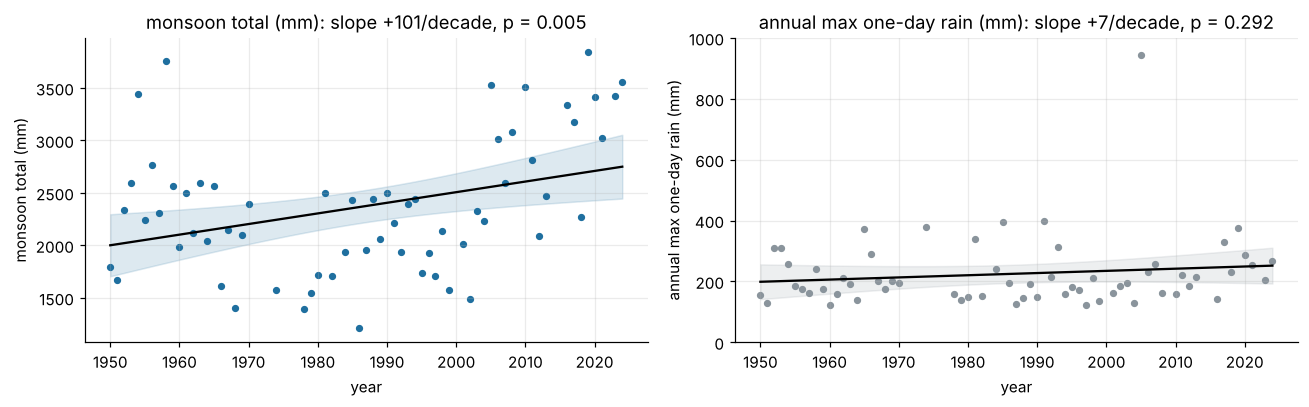

In [28]:
fig, axes = plt.subplots(1, 2, figsize=(12, 3.8))
yrs = annual.index.values
for ax, col, lab, color in [(axes[0], "total_adj_mm", "monsoon total (mm)", BLUE), (axes[1], "max_mm", "annual max one-day rain (mm)", GREY)]:
    m = sm.OLS(annual[col].values, sm.add_constant(yrs.astype(float))).fit()
    grid = np.linspace(yrs.min(), yrs.max(), 100)
    band = m.get_prediction(sm.add_constant(grid)).summary_frame(alpha=0.05)
    ax.scatter(yrs, annual[col], s=14, color=color)
    ax.plot(grid, band["mean"], color="black", lw=1.5)
    ax.fill_between(grid, band.mean_ci_lower, band.mean_ci_upper, color=color, alpha=0.15)
    ax.set(xlabel="year", ylabel=lab, title=f"{lab}: slope {m.params[1] * 10:+.0f}/decade, p = {m.pvalues[1]:.3f}")
axes[1].set_ylim(0, 1000)
fig.tight_layout(); fig.savefig(FIG / "05_trends.png"); plt.show()

**5b. Multiple regression.** What explains how extreme a year's worst day is? We regress the annual maximum on **year**, the **monsoon total** and the number of **wet days**:

max = β₀ + β₁·year + β₂·total + β₃·wet days + ε

A strong positive β₂ with a negative β₃ would mean the same seasonal total packed into fewer wet days produces bigger extremes. 2005 is left out because one 944 mm point would dominate a least-squares fit; its influence is checked separately.

In [29]:
df_mr = annual.drop(2005).reset_index()
df_mr["total_100mm"] = df_mr.total_adj_mm / 100
mr = smf.ols("max_mm ~ year + total_100mm + wet_days", data=df_mr).fit()
print(mr.summary().tables[1])
X = sm.add_constant(df_mr[["year", "total_100mm", "wet_days"]])
vif = {c: variance_inflation_factor(X.values, i) for i, c in enumerate(X.columns) if c != "const"}
print(f"R2 = {mr.rsquared:.3f}, adjusted R2 = {mr.rsquared_adj:.3f}, overall F = {mr.fvalue:.2f}, p = {mr.f_pvalue:.2g}")
print("VIF:", {k: round(v, 2) for k, v in vif.items()}, "(below 5 means no serious multicollinearity)")
print(f"residuals: Shapiro p = {st.shapiro(mr.resid).pvalue:.3f}, Durbin-Watson = {durbin_watson(mr.resid):.2f}")
infl = smf.ols("max_mm ~ year + total_100mm + wet_days", data=annual.reset_index().assign(total_100mm=lambda d: d.total_adj_mm / 100)).fit()
print(f"with 2005 included: R2 = {infl.rsquared:.3f}, Cook's distance of 2005 = {infl.get_influence().cooks_distance[0][annual.index.get_loc(2005)]:.2f}")

                  coef    std err          t      P>|t|      [0.025      0.975]
-------------------------------------------------------------------------------
Intercept     895.5190    855.171      1.047      0.299    -816.291    2607.329
year           -0.3307      0.430     -0.769      0.445      -1.192       0.530
total_100mm     7.2544      2.002      3.623      0.001       3.247      11.262
wet_days       -2.7828      1.106     -2.516      0.015      -4.996      -0.569
R2 = 0.190, adjusted R2 = 0.148, overall F = 4.54, p = 0.0063
VIF: {'year': np.float64(1.18), 'total_100mm': np.float64(2.06), 'wet_days': np.float64(1.84)} (below 5 means no serious multicollinearity)
residuals: Shapiro p = 0.018, Durbin-Watson = 1.88
with 2005 included: R2 = 0.227, Cook's distance of 2005 = 0.88


## 6 · Validation: does the model predict years it never saw?

A model is only useful if it predicts **new** data. We fit everything on **1950–1990** and test it on **1991–2024**:

1. **Return levels.** Count how often the test years exceed the training 10-year and 50-year levels, and compare with Binomial expectations.
2. **Poisson rate.** Compare the predicted total of very heavy days in the test period with the observed total.
3. **Regression.** Compare the out-of-sample error of the trend model for monsoon totals with a no-trend baseline (the training mean).

In [30]:
train = annual.loc[:1990]
test = annual.loc[1991:]
ft = fit_all(train.max_mm.values)
rows = []
for name in ("Gamma", "GEV"):
    for T in (10, 50):
        level = ft[name].isf(1 / T)
        obs = int((test.max_mm > level).sum())
        n, p = len(test), 1 / T
        rows.append({"model": name, "level": f"{T}-yr = {level:.0f} mm", "expected in test": n * p, "observed in test": obs,
                     "P(X >= observed)": st.binom.sf(obs - 1, n, p)})
val_rl = pd.DataFrame(rows)
print(f"train: {len(train)} years (1950-1990) | test: {len(test)} years (1991-2024)")
val_rl

train: 34 years (1950-1990) | test: 29 years (1991-2024)


,model,level,expected in test,observed in test,P(X >= observed)
0,Gamma,10-yr = 304 mm,2.90,5,0.158
1,Gamma,50-yr = 379 mm,0.58,2,0.114
2,GEV,10-yr = 314 mm,2.90,4,0.329
3,GEV,50-yr = 530 mm,0.58,1,0.443


In [31]:
lam_train = train.very_heavy_days.mean()
exp_total = lam_train * len(test)
obs_total = int(test.very_heavy_days.sum())
p_up = st.poisson.sf(obs_total - 1, exp_total)
print(f"Poisson: predicted {exp_total:.0f} very heavy days in {len(test)} test monsoons, observed {obs_total}; P(X >= observed) = {p_up:.3f}")

mt = sm.OLS(train.total_adj_mm.values, sm.add_constant(train.index.values.astype(float))).fit()
pred_t = mt.predict(sm.add_constant(test.index.values.astype(float)))
rmse_trend = np.sqrt(np.mean((test.total_adj_mm.values - pred_t) ** 2))
rmse_mean = np.sqrt(np.mean((test.total_adj_mm.values - train.total_adj_mm.mean()) ** 2))
bias_mean = (test.total_adj_mm - train.total_adj_mm.mean()).mean()
print(f"regression for monsoon totals: RMSE trend model {rmse_trend:.0f} mm vs no-trend mean {rmse_mean:.0f} mm "
      f"(mean of 1950-1990 under-predicts 1991-2024 by {bias_mean:.0f} mm a season)")

Poisson: predicted 100 very heavy days in 29 test monsoons, observed 111; P(X >= observed) = 0.142
regression for monsoon totals: RMSE trend model 1248 mm vs no-trend mean 793 mm (mean of 1950-1990 under-predicts 1991-2024 by 422 mm a season)


### Sources of error and deviation

- **Gaps.** 13 seasons failed the 85% rule. Kept seasons can still miss a storm on an unrecorded day, so heavy-day counts lean low.
- **Recording failures.** The 2005 storm was stored as 461 mm on the wrong day. Without the IMD cross-check, the worst day on record would have entered the analysis at half its size.
- **Precision change.** Many values after 1973 are rounded to whole millimetres. This matters little for extremes of hundreds of millimetres.
- **One gauge.** A single station can miss a storm centred a few kilometres away: Colaba recorded only 74 mm on 26 July 2005.
- **Independence and stationarity.** Binomial and return-period arithmetic assume independent years with a constant p. The rising monsoon total shows conditions are not perfectly stationary.
- **Short record.** 47 to 63 years cannot pin down a 100-year level precisely. That is why every tail estimate here carries a bootstrap interval.

### What validation showed

- **Return levels.** Both models were trained on 1950–1990, and the test years exceeded their 10-year and 50-year levels more often than expected. Gamma's misses are larger: 5 exceedances of its 10-year level where 2.9 were expected, and 2 of its 50-year level where 0.6 were expected. GEV stays closer to expectation, and none of the gaps is significant at 5%.
- **Poisson.** Very heavy days in the test period ran about 10% above the training rate. That is within Poisson noise.
- **Regression.** A straight line fitted on 1950–1990 extrapolated worse than simply using the training mean. Monsoon totals dipped in 1970–89 and rose sharply after 2010 (Section 4, H2), so the early line pointed the wrong way. The full-record trend is real, but a linear trend should not be extrapolated far beyond its data.

## 7 · Export for the website and report

In [32]:
def dist_json(d, kind):
    if kind == "GEV":
        c, l, s = d.args
        return {"type": "gev", "xi": -c, "loc": l, "scale": s}
    if kind == "Gamma":
        a, _, s = d.args
        return {"type": "gamma", "shape": a, "scale": s}
    if kind == "Gumbel":
        l, s = d.args
        return {"type": "gumbel", "loc": l, "scale": s}
    l, s = d.args
    return {"type": "normal", "mean": l, "sd": s}

model = {
    "station": "Bombay/Santacruz (GHCN-Daily IN012070800)",
    "years_used": [int(y) for y in annual.index],
    "annual": [{"year": int(y), "max_mm": round(float(r.max_mm), 1), "date": str(r.max_date.date()),
                "total_mm": round(float(r.total_adj_mm), 0), "very_heavy_days": int(r.very_heavy_days)} for y, r in annual.iterrows()],
    "fits_all": {k: dist_json(v, k) for k, v in fits_all.items()},
    "fits_pre2005": {k: dist_json(v, k) for k, v in fits_pre.items()},
    "gof_pre2005": table_pre[["chi2", "df", "critical", "p_chi2", "p_KS", "AIC", "verdict", "return period of 944 mm (yr)"]].round(4).reset_index().to_dict("records"),
    "gof_all": table_all[["chi2", "df", "critical", "p_chi2", "p_KS", "AIC", "verdict"]].round(4).reset_index().to_dict("records"),
    "gev_all_rl100_ci": [float(ci_all.rl100.iloc[0]), float(ci_all.rl100.iloc[1])],
    "gev_pre_T944_ci": [float(ci.T944.iloc[0]), float(ci.T944.iloc[2])],
    "poisson": {"lambda_very_heavy": float(lam), "lambda_extreme": float(lam_ex),
                "observed": [int(v) for v in pois_obs], "labels": list(pois.index)},
    "monsoon_trend_per_decade": float(trends.loc["monsoon total (mm)", "slope per decade"]),
    "monsoon_trend_p": float(trends.loc["monsoon total (mm)", "p (slope)"]),
    "maxima_trend_p": float(trends.loc["annual max (mm)", "p (slope)"]),
}
payload = json.dumps(model, indent=1, default=float)
(WEB / "model.json").write_text(payload)
(WEB / "model.js").write_text("window.MODEL = " + payload + ";\n")
print("wrote", WEB / "model.json", "and", WEB / "model.js")

wrote /home/claude/repo/docs/data/model.json and /home/claude/repo/docs/data/model.js
